# Final Project

## Load the reviewed dataset where the redundant features r1 and r2 are removed.

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

data_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv'
df = pd.read_csv(data_path)

data_info = {
    "Shape": df.shape,
    "Columns": df.columns.tolist(),
    "Missing Values": df.isnull().sum().sum(),
    "Sample Data": df.head()
}

data_info

Mounted at /content/drive


{'Shape': (19735, 27),
 'Columns': ['date',
  'Appliances',
  'lights',
  'T1',
  'RH_1',
  'T2',
  'RH_2',
  'T3',
  'RH_3',
  'T4',
  'RH_4',
  'T5',
  'RH_5',
  'T6',
  'RH_6',
  'T7',
  'RH_7',
  'T8',
  'RH_8',
  'T9',
  'RH_9',
  'T_out',
  'Press_mm_hg',
  'RH_out',
  'Windspeed',
  'Visibility',
  'Tdewpoint'],
 'Missing Values': 0,
 'Sample Data':                   date  Appliances  lights     T1       RH_1    T2       RH_2  \
 0  2016-01-11 17:00:00          60      30  19.89  47.596667  19.2  44.790000   
 1  2016-01-11 17:10:00          60      30  19.89  46.693333  19.2  44.722500   
 2  2016-01-11 17:20:00          50      30  19.89  46.300000  19.2  44.626667   
 3  2016-01-11 17:30:00          50      40  19.89  46.066667  19.2  44.590000   
 4  2016-01-11 17:40:00          60      40  19.89  46.333333  19.2  44.530000   
 
       T3       RH_3         T4  ...    T8       RH_8         T9   RH_9  \
 0  19.79  44.730000  19.000000  ...  18.2  48.900000  17.033333  45.53  

** Δηλαδή 26 features + 1 feature που είναι το date ολόκληρο

-------

## Initial EDA is already done in the EDA notebook. Here we are doing some feature engineering


In [ ]:
df.dtypes

,0
date,object
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64


-------------

# 1st Trial : We consider all the features as "important" at first to see the model initial performance, interpretability and feature explaination

From the EDA, "Appliances" daily consumptions where very flactuated so we want to see if the Appliance energy usage is strictly connected with its past (lagged) values and the rolling avgs from the past minutes,hour,day. As we said, the data origin is not really representative of the occupants' habits on using the devices. Also, since the data is stationary, it would be helpful to include time-based features to enhance the good prediction of the target value.

**Extract apo datetime ta features : hour, day, weekday**

In [ ]:
# Allazw th dtype giati thelw na kanw extract kapoia "isws" simantika features

df['date'] = pd.to_datetime(df['date'])
# Kanw extract useful features
df['hour'] = df['date'].dt.hour
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.weekday
df['month'] = df['date'].dt.month
df['minute'] = df['date'].dt.minute

# date : metraei san feature opote einai 27
#Edw ginetai 32 (27 + minute, hour, day, weekday, month)

In [ ]:
df.shape

(19735, 32)

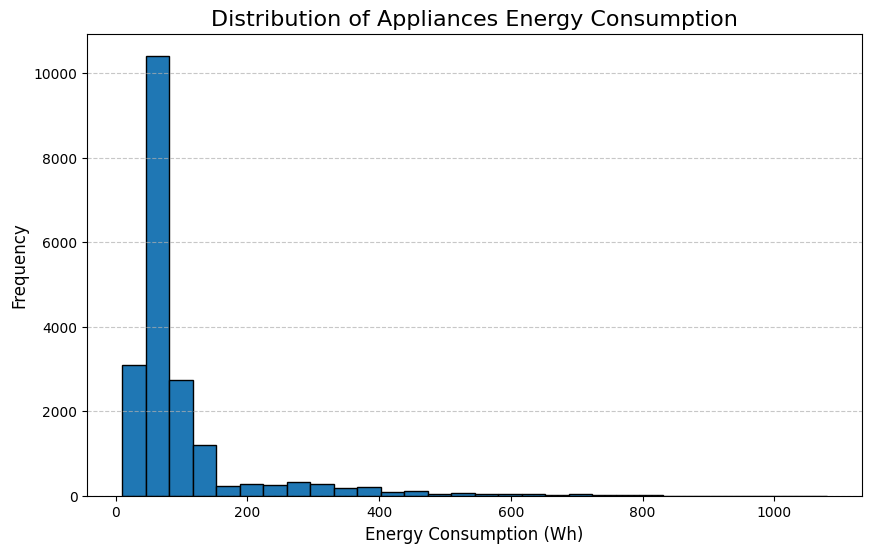


Correlation with Appliances:
Appliances     1.000000
hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
minute         0.013216
T9             0.010010
RH_5           0.006955
weekday        0.003060
day            0.002366
Visibility     0.000230
date          -0.009630
month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['Appliances'], bins=30, edgecolor='black')
plt.title('Distribution of Appliances Energy Consumption', fontsize=16)
plt.xlabel('Energy Consumption (Wh)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

correlation = df.corr()['Appliances'].sort_values(ascending=False)
print("\nCorrelation with Appliances:")
print(correlation)

**Summary Insights**

1. **Summary Statistics:**

 * The target variable Appliances has a mean of 97.7 Wh with a wide standard deviation of 102.5 Wh, indicating significant variability.
 * Environmental variables like T1 (kitchen temperature) and RH_1 (kitchen humidity) exhibit a reasonable range with some variance.

2. Target Variable Distribution:

 * Appliances energy consumption data shows a skewed distribution with a significant number of low-energy readings and a long tail for higher consumption.


---------

In [ ]:
df.head(2)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day,weekday,month,minute
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.7900,19.79,44.73,19.0,...,733.5,92.0,7.000000,63.000000,5.3,17,11,0,1,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.7225,19.79,44.79,19.0,...,733.6,92.0,6.666667,59.166667,5.2,17,11,0,1,10


## Plot the heatmap for the df_31 where we added hour, day, weekday, monthly and we invastigate the top correlations with the appliances

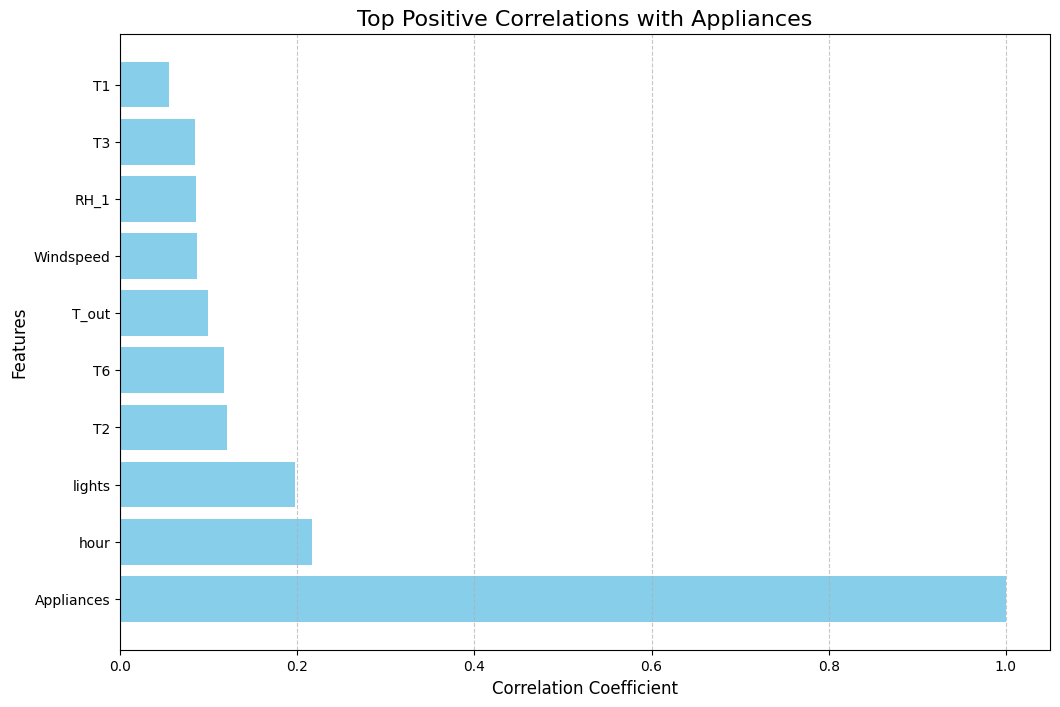

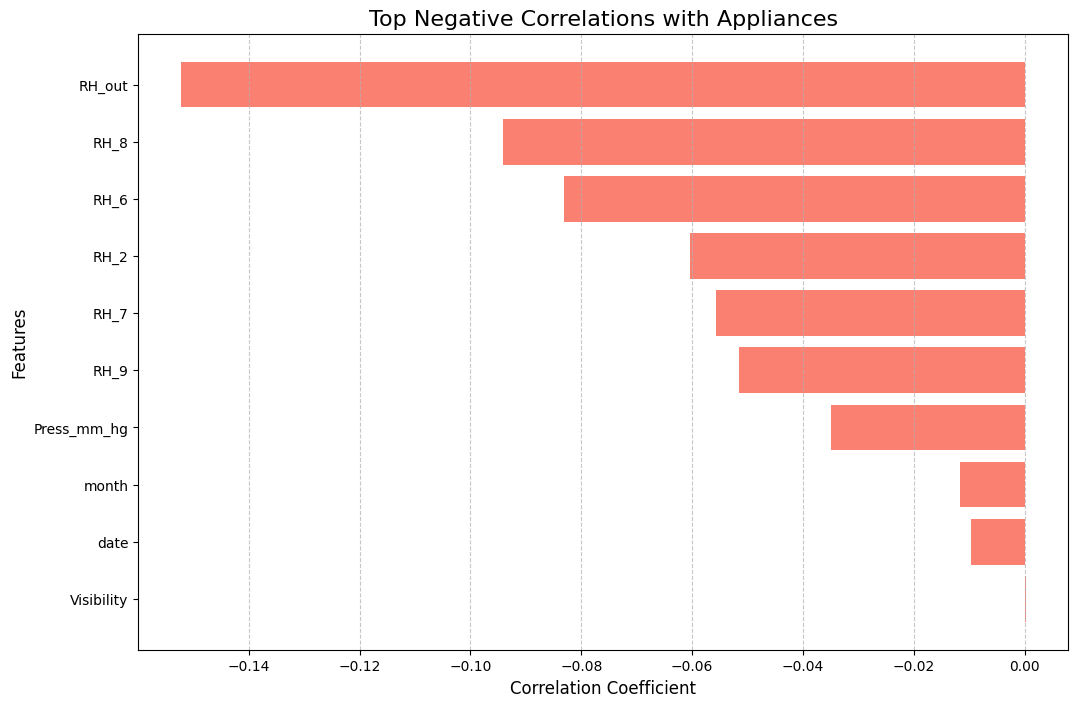

In [ ]:
# Correlation Analysis
top_correlations = correlation.head(10)  #Top 10 positive correlations with the target variable
low_correlations = correlation.tail(10)  #Top 10 negative correlations with the target variable

plt.figure(figsize=(12, 8))
plt.barh(top_correlations.index, top_correlations.values, color='skyblue')
plt.title('Top Positive Correlations with Appliances', fontsize=16)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(12, 8))
plt.barh(low_correlations.index, low_correlations.values, color='salmon')
plt.title('Top Negative Correlations with Appliances', fontsize=16)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

**Insights from Correlations**

1. Correlations
 * **Top Positive Correlations:**

     Lights and T2 (living room temperature) are strongly correlated with Appliances energy consumption, suggesting a close relationship between lighting and energy usage patterns.

 * **Top Negative Correlations:**

     Weather-related variables like RH_out (outdoor relative humidity) and Press_mm_hg (pressure) show weaker or negative correlations.

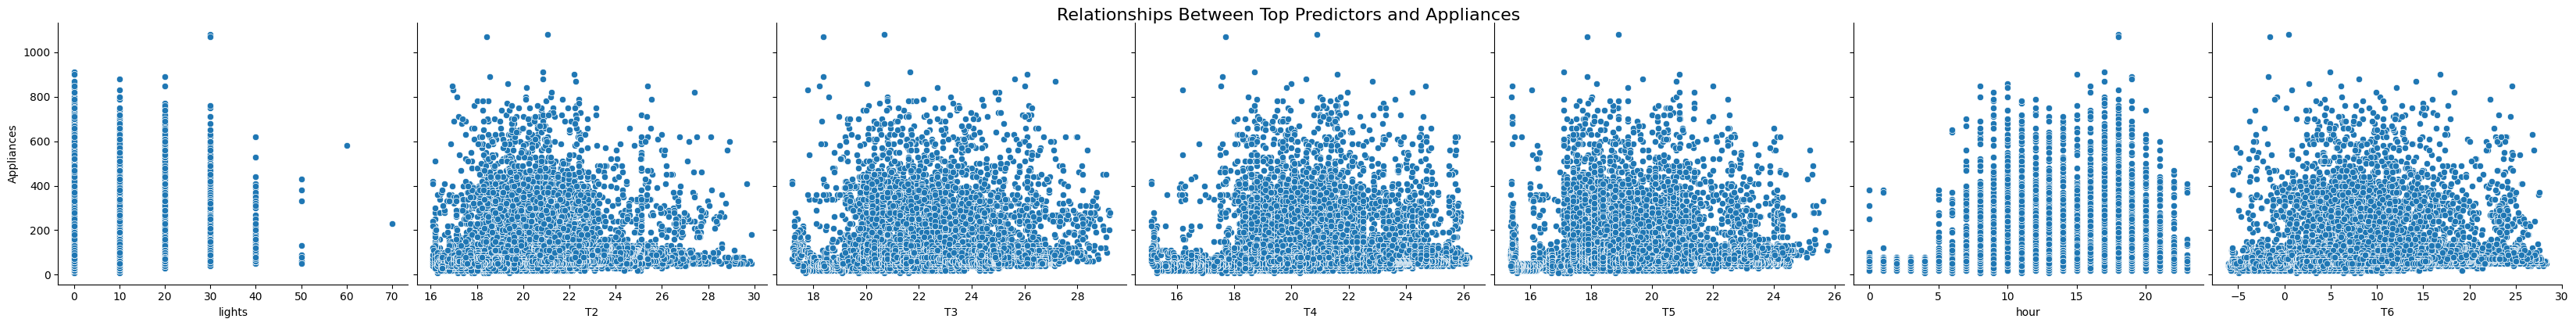

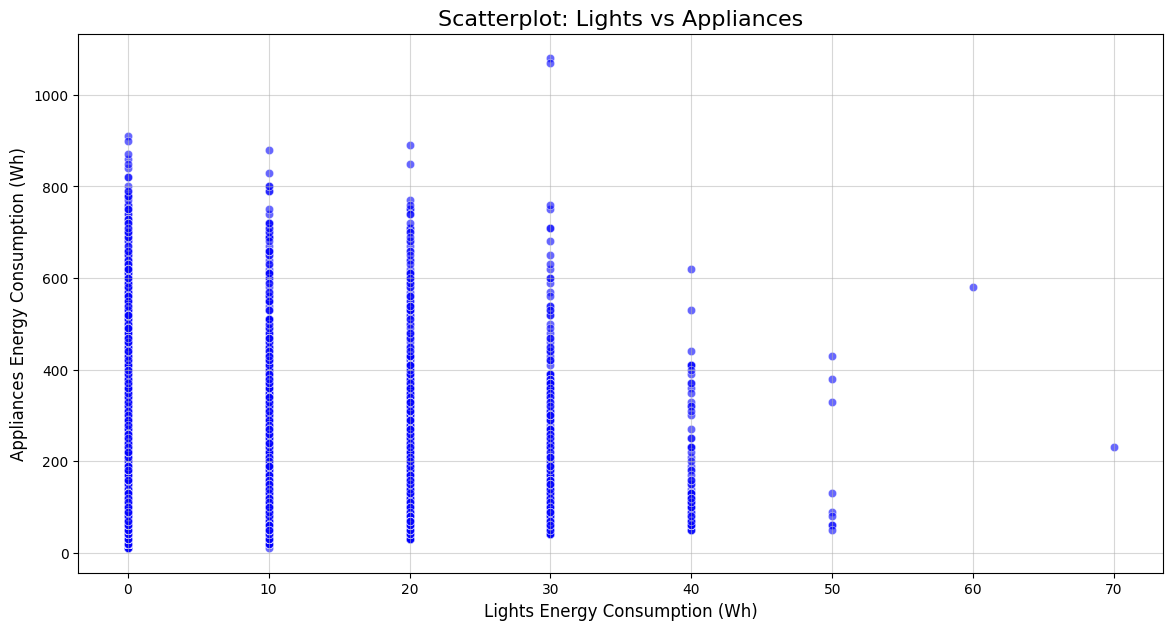

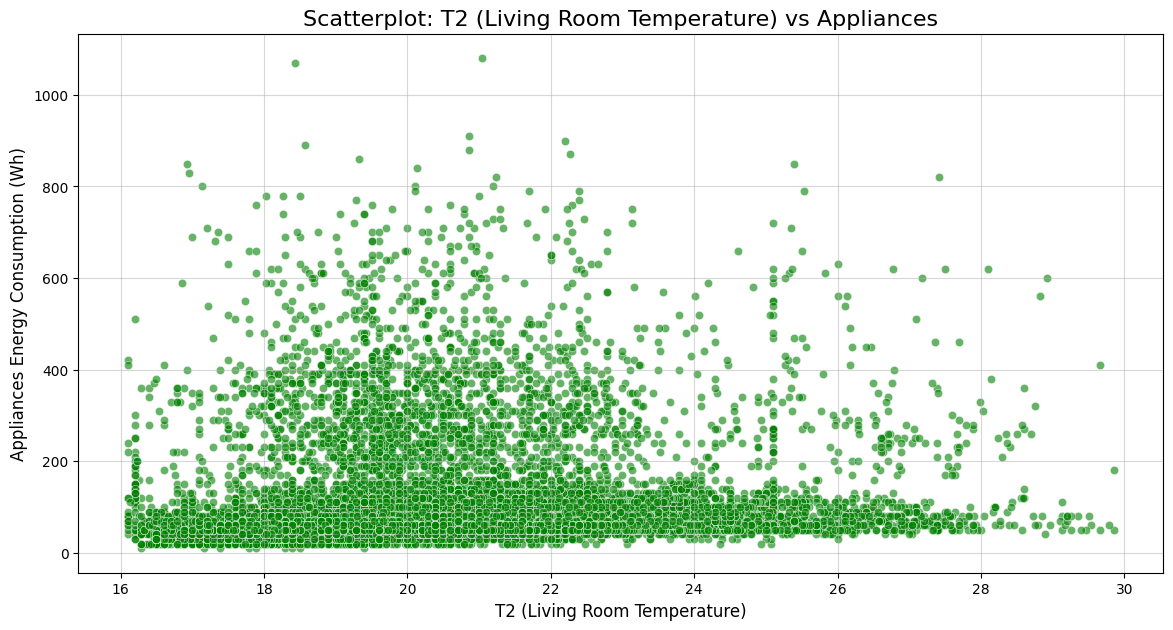

In [ ]:
import seaborn as sns

#Exploring relationships between top positive predictors and Appliances
top_predictors = ['lights', 'T2', 'T3', 'T4', 'T5', 'hour', 'T6']

sns.pairplot(df, x_vars=top_predictors, y_vars=['Appliances'], height=4, aspect=1.2)
plt.suptitle("Relationships Between Top Predictors and Appliances", y=1.02, fontsize=16)
plt.show()

#Lights
plt.figure(figsize=(14, 7))
sns.scatterplot(x='lights', y='Appliances', data=df, alpha=0.6, color='blue')
plt.title('Scatterplot: Lights vs Appliances', fontsize=16)
plt.xlabel('Lights Energy Consumption (Wh)', fontsize=12)
plt.ylabel('Appliances Energy Consumption (Wh)', fontsize=12)
plt.grid(alpha=0.5)
plt.show()

#T2
plt.figure(figsize=(14, 7))
sns.scatterplot(x='T2', y='Appliances', data=df, alpha=0.6, color='green')
plt.title('Scatterplot: T2 (Living Room Temperature) vs Appliances', fontsize=16)
plt.xlabel('T2 (Living Room Temperature)', fontsize=12)
plt.ylabel('Appliances Energy Consumption (Wh)', fontsize=12)
plt.grid(alpha=0.5)
plt.show()

**Insights from Relationships Between Top Predictors and Appliances**

1. Pairplot Summary:

  * A visual overview confirms that predictors like lights and T2 have noticeable patterns with Appliances.
  * Other variables like hour highlight temporal variations in energy consumption.

2. Focused Scatterplots:

 * Lights vs Appliances: A strong positive correlation is evident. Higher lighting energy usage aligns with higher appliance energy consumption, indicating a direct relationship between lighting and overall energy usage by the appliances.

 * T2 (Living Room Temperature) vs Appliances: A moderate positive correlation suggests that living room temperature influences energy usage, potentially linked to more occupancy level in that place.


-------

## Now, we plot the correlations of the features and target value seperately, for every floor and weather features

In [ ]:
(df[df['Appliances'] > 750])

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day,weekday,month,minute
432,2016-01-14 17:00:00,910,0,21.463333,41.693333,20.856667,38.363333,21.666667,43.930000,18.700000,...,747.900000,76.000000,7.000000,40.000000,0.700000,17,14,3,1,0
443,2016-01-14 18:50:00,790,10,22.166667,40.500000,21.700000,38.626667,22.166667,42.133333,18.790000,...,748.433333,76.833333,6.833333,40.000000,0.350000,18,14,3,1,50
731,2016-01-16 18:50:00,1080,30,21.930000,42.766667,21.040000,38.080000,20.700000,40.633333,20.890000,...,765.033333,85.500000,3.666667,40.000000,-0.083333,18,16,5,1,50
867,2016-01-17 17:30:00,800,10,21.500000,36.760000,20.100000,36.077273,20.790000,37.260000,21.000000,...,764.850000,78.000000,2.000000,40.000000,-3.500000,17,17,6,1,30
868,2016-01-17 17:40:00,790,10,21.566667,38.626667,20.100000,37.040909,20.790000,37.260000,21.066667,...,764.833333,79.666667,2.000000,40.000000,-3.466667,17,17,6,1,40
1307,2016-01-20 18:50:00,830,10,17.600000,38.090000,16.960000,38.030000,17.790000,37.390000,16.200000,...,760.700000,92.500000,2.000000,48.500000,-1.216667,18,20,2,1,50
1451,2016-01-21 18:50:00,1070,30,19.600000,34.300000,18.426667,33.963333,18.390000,36.930000,17.700000,...,764.533333,82.833333,1.000000,64.166667,-3.216667,18,21,3,1,50
1452,2016-01-21 19:00:00,890,20,19.730000,37.863333,18.566667,34.090000,18.390000,36.863333,17.600000,...,764.500000,84.000000,1.000000,64.000000,-3.200000,19,21,3,1,0
1821,2016-01-24 08:30:00,850,20,17.600000,44.166667,16.926667,43.230000,18.230000,43.290000,17.523333,...,767.400000,95.500000,6.000000,52.000000,5.650000,8,24,6,1,30
1823,2016-01-24 08:50:00,800,10,17.790000,45.490000,17.133333,43.566667,18.596667,45.693333,18.493333,...,767.466667,95.166667,5.333333,44.000000,5.750000,8,24,6,1,50


As we see, the high Appliances energy usage is not being influanced by the "big" sensor-related data values because for the same values we have small energy usage too in other dates. (The automatically generated plots by google collab)

In [ ]:
print(df.shape)
df.head(3)

(19735, 32)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day,weekday,month,minute
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,733.5,92.0,7.000000,63.000000,5.3,17,11,0,1,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,733.6,92.0,6.666667,59.166667,5.2,17,11,0,1,10
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,733.7,92.0,6.333333,55.333333,5.1,17,11,0,1,20


## At this step, we will examine the interdepedence of the appliances beyond minutes

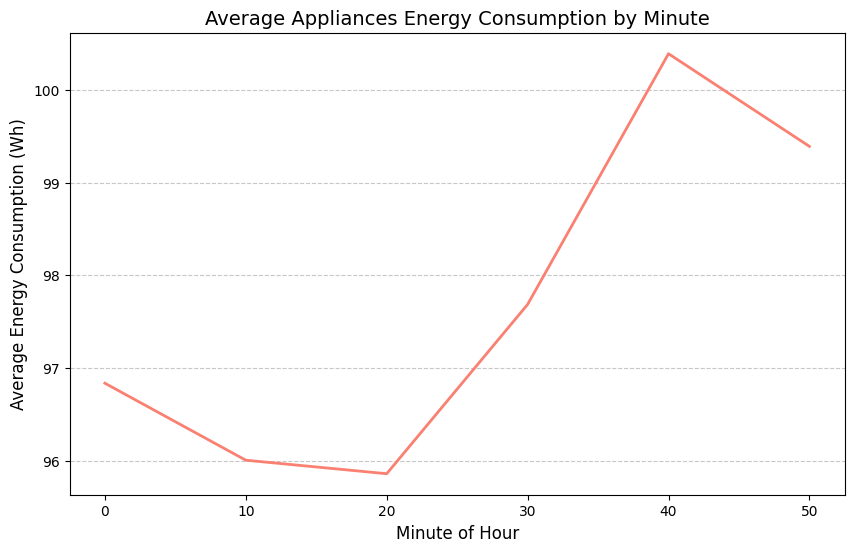

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))


df.groupby('minute')['Appliances'].mean().plot(ax=ax, color='salmon', linewidth=2)
ax.set_title('Average Appliances Energy Consumption by Minute', fontsize=14)
ax.set_xlabel('Minute of Hour', fontsize=12)
ax.set_ylabel('Average Energy Consumption (Wh)', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

**Visualizations of Appliances Energy Consumption**

Minute-Level Variability:

 * Minute-wise averages show smaller variations, as the dataset primarily captures 10-minute intervals. We see that for an already usage of Appliances of about 20 minutes will probably give us +10Wh approximately.

In [ ]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'hour', 'day', 'weekday', 'month', 'minute'],
      dtype='object')

---------------------------

## Data preperation - Modeling - Feature Importance

In [ ]:
save_path1 = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_before_1st_GBM.csv'
df.to_csv(save_path1, index=False)

In [ ]:
df = pd.read_csv(save_path1)
df.dtypes

,0
date,object
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64


In [ ]:
import plotly.express as px
import pandas as pd

hourly_avg = df.groupby('hour')[['Appliances', 'lights']].mean().reset_index()

fig = px.line(hourly_avg, x='hour', y=['Appliances', 'lights'],
              labels={'value': 'Energy Consumption (Wh)', 'hour': 'Hour of the Day'},
              title='Energy Consumption of Appliances and Lights by Hour')

fig.show()

The energy consumption of lights remains relatively low and stable throughout the day.

There is a slight increase in the evening hours (~18:00 to 22:00), likely due to increased indoor activity and reliance on artificial lighting.

For this reason, we can use the lagged values of lights as additional features and the feature light as a binary (0 = OFF , 1 = ON)

In [ ]:
df_fake = df.copy()
df_fake['date'] = pd.to_datetime(df_fake['date'])
print(df_fake.head(2))

                 date  Appliances  lights     T1       RH_1    T2     RH_2  \
0 2016-01-11 17:00:00          60      30  19.89  47.596667  19.2  44.7900   
1 2016-01-11 17:10:00          60      30  19.89  46.693333  19.2  44.7225   

      T3   RH_3    T4  ...  Press_mm_hg  RH_out  Windspeed  Visibility  \
0  19.79  44.73  19.0  ...        733.5    92.0   7.000000   63.000000   
1  19.79  44.79  19.0  ...        733.6    92.0   6.666667   59.166667   

   Tdewpoint  hour  day  weekday  month  minute  
0        5.3    17   11        0      1       0  
1        5.2    17   11        0      1      10  

[2 rows x 32 columns]


In [ ]:
df_fake['NSM'] = df_fake['hour'] * 3600 + df_fake['minute'] * 60

rolling_window = 6
df_fake['lights_rolling_avg'] = df_fake['lights'].rolling(window=rolling_window, min_periods=1).mean()
df_fake['appliances_rolling_avg'] = df_fake['Appliances'].rolling(window=rolling_window, min_periods=1).mean()

lag_features = ['lights', 'Appliances']
for feature in lag_features:
    df_fake[f'{feature}_lag_2'] = df_fake[feature].shift(2)

df_fake.dropna(inplace=True)
df_fake.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'hour', 'day', 'weekday', 'month', 'minute',
       'NSM', 'lights_rolling_avg', 'appliances_rolling_avg', 'lights_lag_2',
       'Appliances_lag_2'],
      dtype='object')

In [ ]:
save_path2 = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_fake.csv'
df_fake.to_csv(save_path2, index=False)

In [ ]:
df_fake.shape

(19733, 37)

-> The higher R² indicates better generalization and effective learning from more training data. To ensure robustness we will apply `TimeSeriesSplit` for CV

In [ ]:
df_fake['lights'] = df_fake['lights'].apply(lambda x: 1 if x > 0 else 0)
df_fake.dtypes

,0
date,datetime64[ns]
Appliances,int64
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64


Cross-Validation Results: {'Mean RMSE (TimeSeriesSplit)': 74.45823397704225, 'Std RMSE (TimeSeriesSplit)': 7.141207524870175, 'Mean MSE (TimeSeriesSplit)': 5595.025451893232, 'Std MSE (TimeSeriesSplit)': 1063.9105419006394, 'Mean R² (TimeSeriesSplit)': 0.40585045000205094, 'Std R² (TimeSeriesSplit)': 0.15783040731516373, 'R² Scores (Each Fold)': [0.325432168253168, 0.4843460536794957, 0.5646714764513342, 0.5202624476777256, 0.134540103948531], 'MSE Scores (Each Fold)': [6554.552106670297, 5557.342447931251, 4269.789923679741, 4592.602399959345, 7000.840381225525]}


 97%|=================== | 15356/15786 [00:16<00:00]       

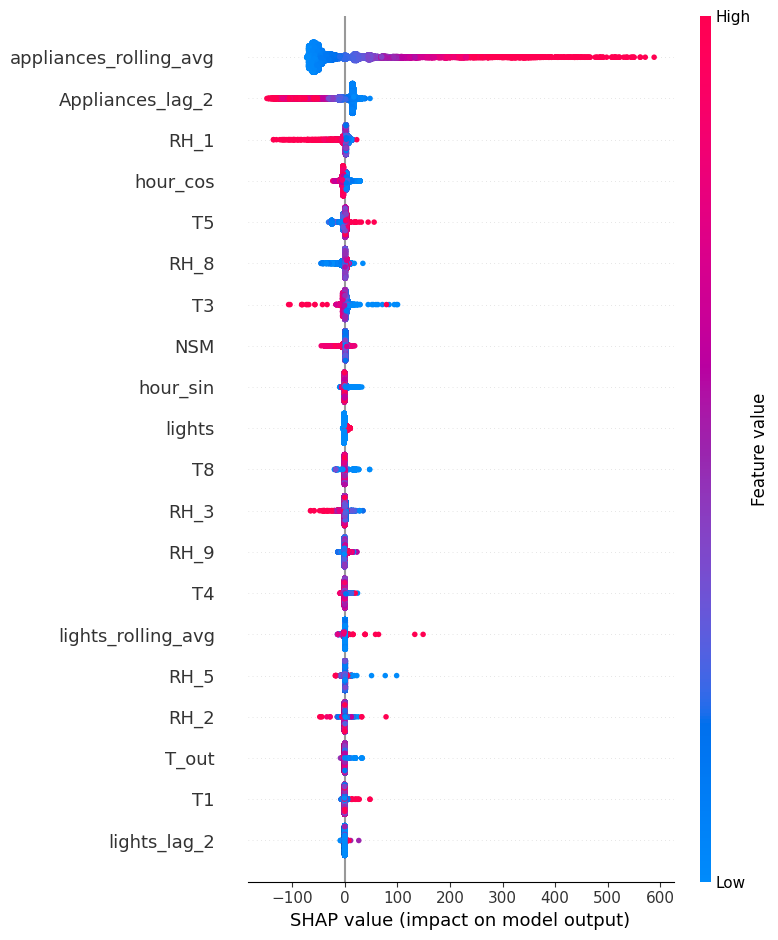

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import shap

#Feature Engineering
df_fake['hour_sin'] = np.sin(2 * np.pi * df_fake['hour'] / 24)
df_fake['hour_cos'] = np.cos(2 * np.pi * df_fake['hour'] / 24)
df_fake['weekday_sin'] = np.sin(2 * np.pi * df_fake['weekday'] / 7)
df_fake['weekday_cos'] = np.cos(2 * np.pi * df_fake['weekday'] / 7)

columns_to_drop = ['hour', 'minute', 'day', 'month', 'weekday', 'date']
df_fake = df_fake.drop(columns=columns_to_drop)

#Normalization
scaler = MinMaxScaler()
continuous_features = df_fake.select_dtypes(include=['float64', 'int64']).columns.difference(['Appliances', 'lights'])
df_fake[continuous_features] = scaler.fit_transform(df_fake[continuous_features])

X = df_fake.drop(columns=['Appliances'])
y = df_fake['Appliances']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)


# ------TimeSeriesSplit for cross-validation, which respects the temporal order
tscv = TimeSeriesSplit(n_splits=5)

mse_scores = []
r2_scores = []

for train_index, test_index in tscv.split(X):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    gbm = GradientBoostingRegressor(random_state=42)
    gbm.fit(X_train_fold, y_train_fold)

    y_pred_fold = gbm.predict(X_test_fold)
    mse_scores.append(mean_squared_error(y_test_fold, y_pred_fold))
    r2_scores.append(r2_score(y_test_fold, y_pred_fold))

#Metrics
cv_results = {
    "Mean RMSE (TimeSeriesSplit)": np.mean(np.sqrt(mse_scores)),
    "Std RMSE (TimeSeriesSplit)": np.std(np.sqrt(mse_scores)),
    "Mean MSE (TimeSeriesSplit)": np.mean(mse_scores),
    "Std MSE (TimeSeriesSplit)": np.std(mse_scores),
    "Mean R² (TimeSeriesSplit)": np.mean(r2_scores),
    "Std R² (TimeSeriesSplit)": np.std(r2_scores),
    "R² Scores (Each Fold)": r2_scores,
    "MSE Scores (Each Fold)": mse_scores
}

print("Cross-Validation Results:", cv_results)

# SHAP Analysis
explainer = shap.Explainer(gbm, X_train)
shap_values = explainer(X_train)
shap.summary_plot(shap_values, X_train)


**Evaluate the Metric**
Mean R² (0.4058): The model explains around 41% of the variance in the target, which indicates there is room for improvement but suggests the model has learned meaningful patterns.

**Insights from SHAP :**
 * Top Features: appliances_rolling_avg, Appliances_lag_1, and Appliances_lag_2 are the most influential predictors.

 * Features like hour_cos, RH_1, lights, and NSM also contribute significantly.

 * The rolling average and lagged values of Appliances suggest strong temporal dependencies.
Environmental factors (e.g., humidity, temperature) and time-related features (e.g., NSM, hour_cos) play smaller but meaningful roles.

--------

In [ ]:
save_path3 = '/content/drive/MyDrive/Machine_Learning/Final_Project/df_fake_37.csv'

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv(save_path3)
df.head(2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,lights_rolling_avg,appliances_rolling_avg,lights_lag_1,lights_lag_2,Appliances_lag_1,Appliances_lag_2,hour_sin,hour_cos,weekday_sin,weekday_cos
0,50,0.428571,0.32735,0.530502,0.225345,0.679445,0.215188,0.755569,0.344745,0.778062,...,0.580645,0.043269,0.428571,0.428571,0.046729,0.046729,0.017037,0.37059,0.5,1.0
1,50,0.571429,0.32735,0.524080,0.225345,0.678414,0.215188,0.758685,0.341441,0.770949,...,0.629032,0.040865,0.428571,0.428571,0.037383,0.046729,0.017037,0.37059,0.5,1.0


## Improving the model and reducing the feature dimension

In [ ]:
# We save the X_37 and y_37 data
save_path_X = '/content/drive/MyDrive/Machine_Learning/Final_Project/X_dataset_37.csv'
X.to_csv(save_path_X, index=False)

save_path_y = '/content/drive/MyDrive/Machine_Learning/Final_Project/y_dataset_37.csv'
y.to_csv(save_path_y, index=False)

In [ ]:
from sklearn.model_selection import GridSearchCV

top_features = [
    'appliances_rolling_avg', 'Appliances_lag_2', 'RH_1',
    'hour_cos', 'T5', 'RH_8', 'T3', 'NSM']
X_reduced = X[top_features]

#GridSearchCV
#Parameter grid
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=TimeSeriesSplit(n_splits=5)
)

grid_search.fit(X_reduced, y)
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best R² Score:", best_score)

Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best R² Score: 0.582440878043441


## Training the GBM with the best hyper-parameters

In [ ]:
print(X_reduced.shape)
X_train, X_test, y_train, y_test = train_test_split(X_reduced, y, test_size=0.2, random_state=42, shuffle=False)

(19733, 8)


TimeSeriesSplit cross-validation is not necessary at this point since we are now evaluating the final model on the test set. The test set serves as the validation to ensure the model generalizes well, based on the reduced features and optimized parameters. We already applied TimeSeriesSplit during hyperparameter tuning (via GridSearchCV) to find the best parameters.Now, we are evaluating the final model performance on a held-out test set to check its real-world applicability.


Test MSE: 3419.4397573307606
Test R²: 0.587423503261234


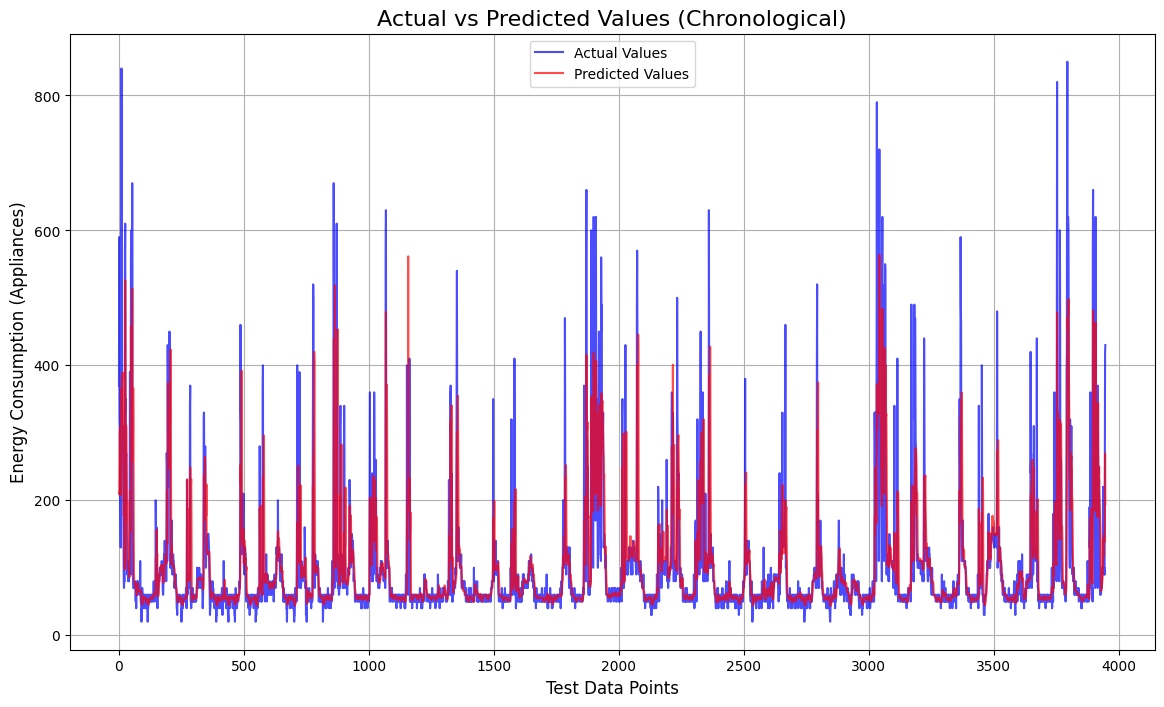

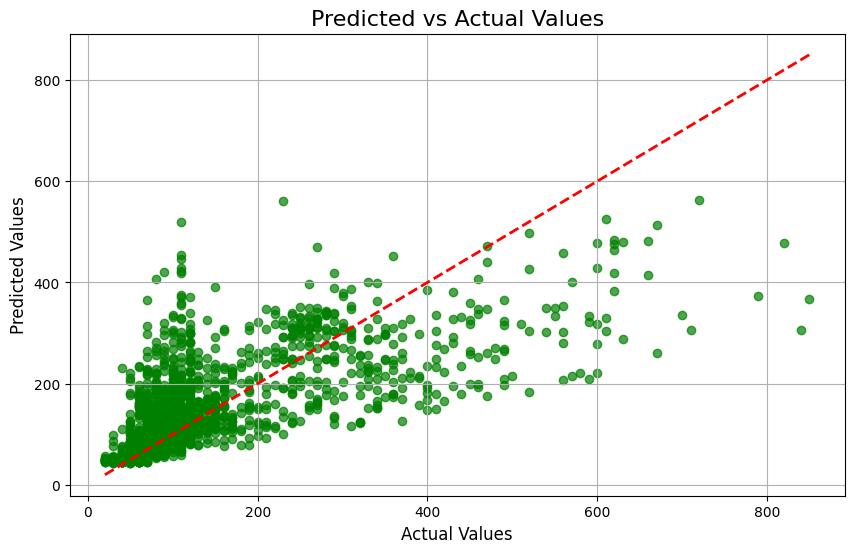

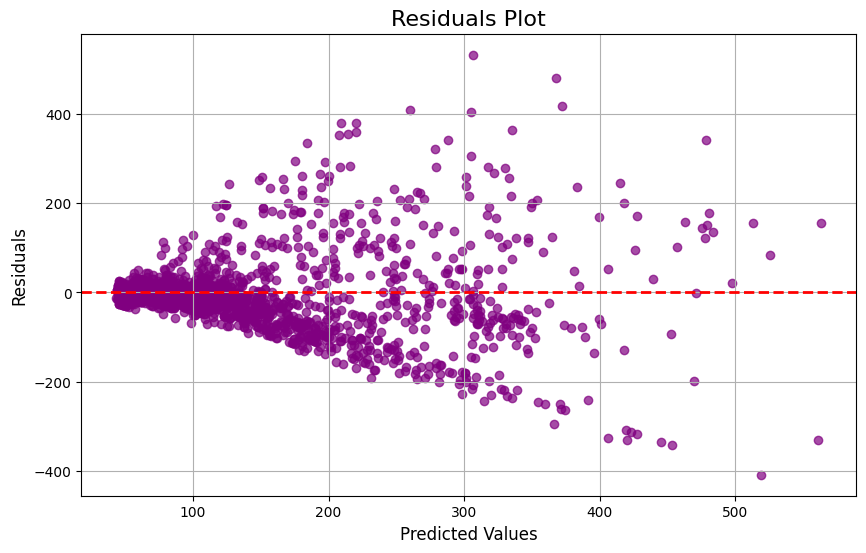

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

#Final Model with best parameters
final_gbm = GradientBoostingRegressor(
    learning_rate=0.01,
    max_depth=5,
    n_estimators=300,
    subsample=0.8,
    random_state=42
)
final_gbm.fit(X_train, y_train)

y_pred = final_gbm.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {test_mse}")
print(f"Test R²: {test_r2}")

#Actual vs Predicted values
plt.figure(figsize=(14, 8))
plt.plot(range(len(y_test)), y_test, label='Actual Values', color='blue', alpha=0.7)
plt.plot(range(len(y_test)), y_pred, label='Predicted Values', color='red', alpha=0.7)
plt.title('Actual vs Predicted Values (Chronological)', fontsize=16)
plt.xlabel('Test Data Points', fontsize=12)
plt.ylabel('Energy Consumption (Appliances)', fontsize=12)
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Predicted vs Actual Values', fontsize=16)
plt.xlabel('Actual Values', fontsize=12)
plt.ylabel('Predicted Values', fontsize=12)
plt.grid()
plt.show()

#Residuals
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.title('Residuals Plot', fontsize=16)
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid()
plt.show()


**Insights from the Results**

1. The predictions closely follow the actual values for most data points, indicating that the model captures the trends well.
However, there are some regions where the model struggles with larger peaks or dips in energy consumption

2. A good model should have points clustered close to the red line.
In this case most points are reasonably close to the line, indicating decent accuracy. However, there is some dispersion, especially for higher values, showing the model has more difficulty predicting higher energy usage.

3. Most residuals are centered around 0, which is good. However, for higher predicted values, the residuals appear more dispersed, indicating the model may be biased for higher energy consumption.


 * **Feature Interpretations**
1. `appliances_rolling_avg`
Interpretation: The rolling average of appliance energy consumption is the most influential feature.
Behavior:
High rolling averages (red points) push the prediction higher.
Low rolling averages (blue points) push the prediction lower.
2. `Appliances_lag_1 and Appliances_lag_2`
Interpretation: The lagged energy consumption values (e.g., one and two time steps ago) are critical predictors.
Behavior:
Higher lagged values are associated with higher predictions.
This suggests strong temporal dependencies in the data.
3. `hour_cos`
Interpretation: The cosine of the hour is an important time-related feature.
Behavior:
Indicates time of day impacts energy consumption patterns.
Specific times (e.g., morning vs. evening) influence the prediction.
4. `RH_1 (Relative Humidity in Zone 1)`
Interpretation: Indoor humidity in the first zone is moderately influential.
Behavior:
Higher humidity (red) may correlate with higher energy usage, possibly due to HVAC system activity.
5. `lights`
Interpretation: The energy usage of lights contributes to the prediction.
Behavior:
Higher lighting energy consumption (red) is associated with higher appliance energy usage.
6. `NSM (Number of Seconds from Midnight)`
Interpretation: A proxy for the time of day, with a consistent contribution to predictions.
Behavior:
Captures temporal patterns in energy consumption.
7.` hour_sin`
Interpretation: The sine transformation of the hour complements hour_cos, capturing time-related cyclic effects.
Behavior:
Specific times of the day drive energy usage predictions.
8.` Other Features (RH_8, T4, T3, etc.)`
Interpretation: These have progressively lower importance.
Behavior:
Features like temperature (T4, T3) and humidity (RH_8) have less consistent but still meaningful contributions.


* **Key Insights**

The model relies heavily on temporal features (appliances_rolling_avg, lagged values, hour_cos, NSM) and environmental factors (RH_1, lights).
Less important features could potentially be dropped to simplify the model, but they still provide minor predictive power.



We see that at the top features of shap, the Temperature sensors and weather sensors from outside aren't included as main predictors. We chose the first 8 features to see their predictive ability on "Appliances". Though, we observe that the model is a bit biased at some intervals and this can be caused because we ignored the weather related data presence. A future alternative approach would be if we applied again some feature engineering for more complex relationships between features and/or dumping, unifying the "indepedent" features that were extremely correlated from the heatmap and see if the model would have captured better patterns. Because we have an acceptable R2_score(0.59) we can leave it here.

In [ ]:
y_train_residuals = y_train - final_gbm.predict(X_train)
y_test_residuals = y_test - final_gbm.predict(X_test)

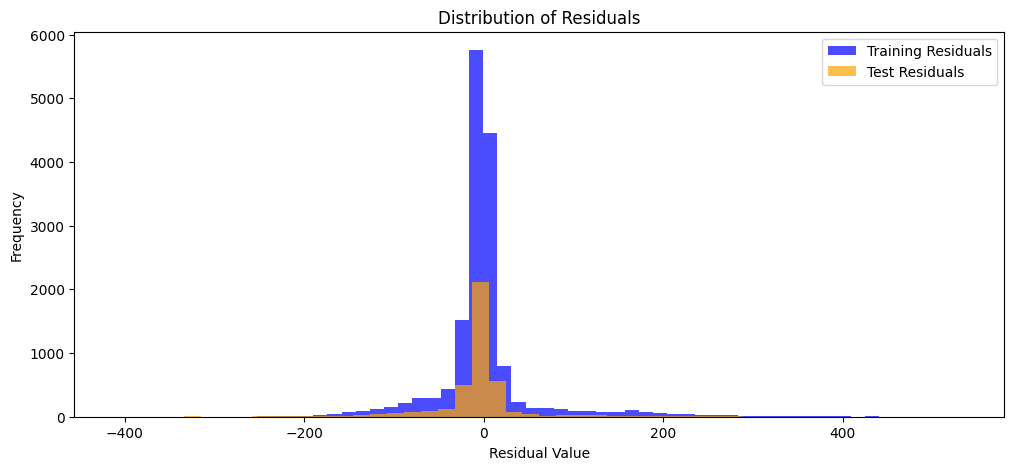

In [ ]:
plt.figure(figsize=(12, 5))
plt.hist(y_train_residuals, bins=50, alpha=0.7, label='Training Residuals', color='blue')
plt.hist(y_test_residuals, bins=50, alpha=0.7, label='Test Residuals', color='orange')
plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.legend()

In [ ]:
X_reduced.columns

Index(['appliances_rolling_avg', 'Appliances_lag_2', 'RH_1', 'hour_cos', 'T5',
       'RH_8', 'T3', 'NSM'],
      dtype='object')

## Save the model

In [ ]:
import joblib

# Save the model
joblib.dump(final_gbm, 'final_gbm_model.pkl')
print("Model saved to 'final_gbm_model.pkl'")

Model saved to 'final_gbm_model.pkl'


---------

## Other trial to see how the occupants are behavioring at the house (More feature engineering to compare the significance of present values to predict the 40 minutes) - Multistep forecasting

In [ ]:
# Adding more features at

save_path_X_reduced = '/content/drive/MyDrive/Machine_Learning/Final_Project/X_reduced.csv'
save_path_y = '/content/drive/MyDrive/Machine_Learning/Final_Project/y.csv'
X_reduced.to_csv((save_path_X_reduced), index=False)
y.to_csv(save_path_y, index=False)

In [ ]:
X_reduced = pd.read_csv(save_path_X_reduced)
y = pd.read_csv(save_path_y)
df_new = pd.concat([X_reduced, y], axis=1)

#multi-step forecast targets
forecast_steps = [1, 3, 6]  #10 min, 30 min, and 1 hour ahead
for step in forecast_steps:
    df_new[f'Appliances_next_{step}'] = df_new['Appliances'].shift(-step)


for lag in range(3, 5):#1 to 6 lags (up to 1 hour back)
    df_new[f'Appliances_lag_{lag}'] = df_new['Appliances'].shift(lag)

df_new['Appliances_rolling_mean_3'] = df_new['Appliances'].rolling(window=3).mean()  #30-min average


df_new = df_new.dropna()
X = df_new.drop(columns=['Appliances', 'Appliances_next_1', 'Appliances_next_3', 'Appliances_next_6'])
y_10min = df_new['Appliances_next_1']  # 10-minute ahead target
y_30min = df_new['Appliances_next_3']  # 30-minute ahead target
y_1hour = df_new['Appliances_next_6']  # 1-hour ahead target

df_new.shape

(19719, 15)

In [ ]:
#10-minute forecast
X_train_10min, X_test_10min, y_train_10min, y_test_10min = train_test_split(
    X, y_10min, test_size=0.2, shuffle=False, random_state=42)

#30-minute forecast
X_train_30min, X_test_30min, y_train_30min, y_test_30min = train_test_split(
    X, y_30min, test_size=0.2, shuffle=False, random_state=42)

#1-hour forecast
X_train_1hour, X_test_1hour, y_train_1hour, y_test_1hour = train_test_split(
    X, y_1hour, test_size=0.2, shuffle=False, random_state=42)

10-Minute Forecast - MSE: 5238.621389492767, R²: 0.36444145729267385
30-Minute Forecast - MSE: 7968.671970794391, R²: 0.03197125397943534
1-Hour Forecast - MSE: 6675.322997478738, R²: 0.18601680122461928


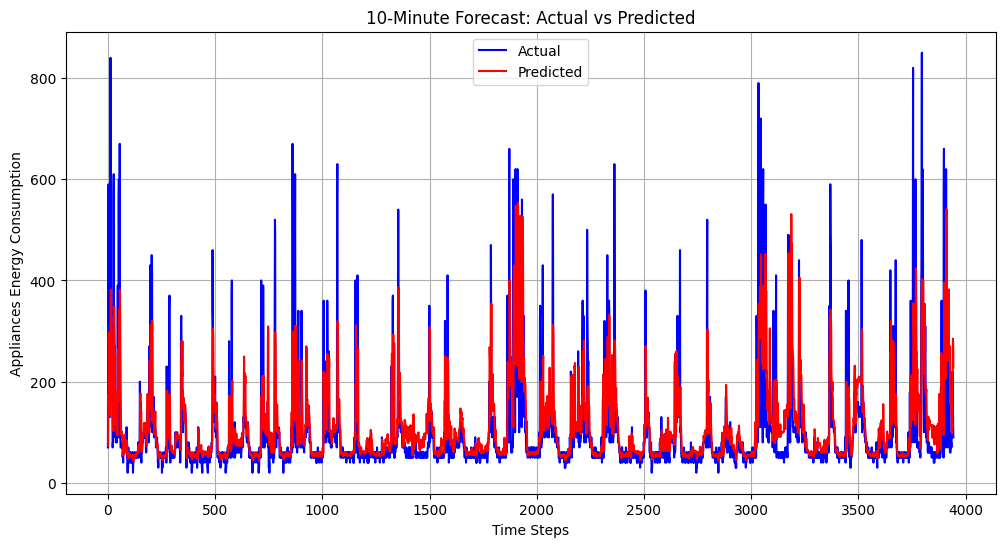

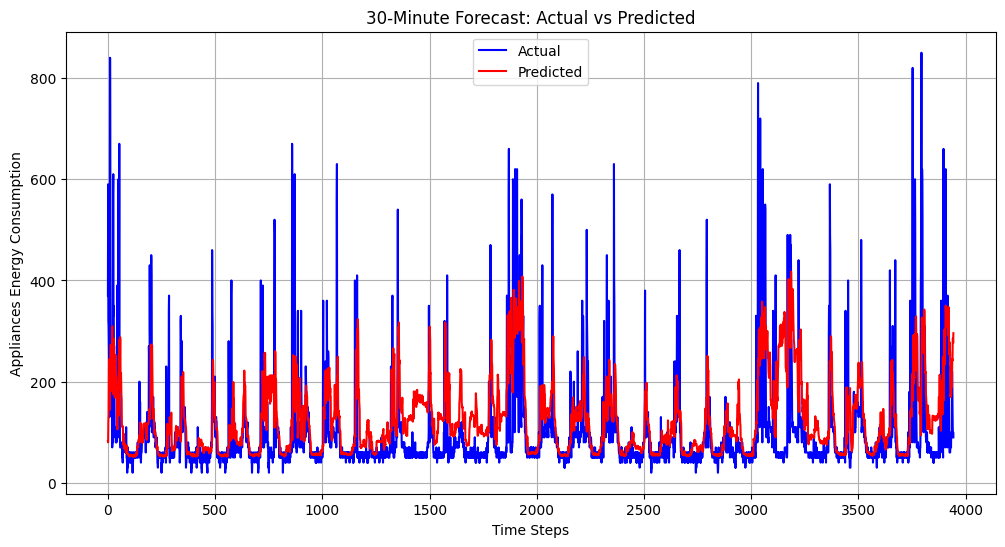

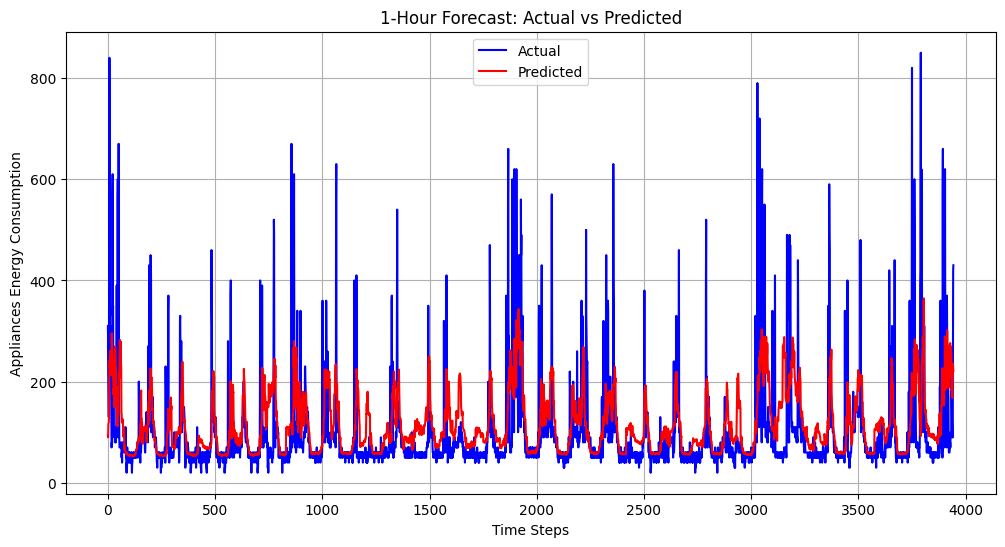

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

#10-minutes
gbm_10min = GradientBoostingRegressor(learning_rate=0.01,max_depth=5, n_estimators=300, subsample=0.8, random_state=42)
gbm_10min.fit(X_train_10min, y_train_10min)

y_pred_10min = gbm_10min.predict(X_test_10min)
mse_10min = mean_squared_error(y_test_10min, y_pred_10min)
r2_10min = r2_score(y_test_10min, y_pred_10min)

print(f"10-Minute Forecast - MSE: {mse_10min}, R²: {r2_10min}")

#30-minutes
gbm_30min = GradientBoostingRegressor(learning_rate=0.01,max_depth=5, n_estimators=300, subsample=0.8, random_state=42)
gbm_30min.fit(X_train_30min, y_train_30min)

y_pred_30min = gbm_30min.predict(X_test_30min)
mse_30min = mean_squared_error(y_test_30min, y_pred_30min)
r2_30min = r2_score(y_test_30min, y_pred_30min)

print(f"30-Minute Forecast - MSE: {mse_30min}, R²: {r2_30min}")

#1-hour
gbm_1hour = GradientBoostingRegressor(learning_rate=0.01,max_depth=5, n_estimators=300, subsample=0.8, random_state=42)
gbm_1hour.fit(X_train_1hour, y_train_1hour)

y_pred_1hour = gbm_1hour.predict(X_test_1hour)
mse_1hour = mean_squared_error(y_test_1hour, y_pred_1hour)
r2_1hour = r2_score(y_test_1hour, y_pred_1hour)

print(f"1-Hour Forecast - MSE: {mse_1hour}, R²: {r2_1hour}")


#Actual vs predicted for 10-minute, 30-minute and 1-hour forecast
plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_10min)), y_test_10min, label='Actual', color='blue')
plt.plot(range(len(y_pred_10min)), y_pred_10min, label='Predicted', color='red')
plt.title('10-Minute Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_30min)), y_test_30min, label='Actual', color='blue')
plt.plot(range(len(y_pred_30min)), y_pred_30min, label='Predicted', color='red')
plt.title('30-Minute Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_1hour)), y_test_1hour, label='Actual', color='blue')
plt.plot(range(len(y_pred_1hour)), y_pred_1hour, label='Predicted', color='red')
plt.title('1-Hour Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()

------

## 2nd Trial : Reduce the dimensions of the dataset with the correlation map (throw every weak corr of indipedent variables with Appliances + high corr between indipedent varibles and keep the most correlated one with the target)

In [ ]:
file_path = '/content/drive/MyDrive/Machine_Learning/Final_Project/energydata_reviewed.csv'
df = pd.read_csv(file_path)
df.head(2)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.7900,19.79,44.73,19.0,...,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.7225,19.79,44.79,19.0,...,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2


In [ ]:
df['date'] = pd.to_datetime(df['date'])

correlation_with_target = df.corr()['Appliances'].sort_values(ascending=False)

correlation_with_target = df.corr()['Appliances'].sort_values(ascending=False)
feature_importance_df = pd.DataFrame({
    "Feature": correlation_with_target.index,
    "Correlation with Appliances": correlation_with_target.values
})

print(feature_importance_df)

        Feature  Correlation with Appliances
0    Appliances                     1.000000
1        lights                     0.197278
2            T2                     0.120073
3            T6                     0.117638
4         T_out                     0.099155
5     Windspeed                     0.087122
6          RH_1                     0.086031
7            T3                     0.085060
8            T1                     0.055447
9            T4                     0.040281
10           T8                     0.039572
11         RH_3                     0.036292
12           T7                     0.025801
13           T5                     0.019760
14         RH_4                     0.016965
15    Tdewpoint                     0.015353
16           T9                     0.010010
17         RH_5                     0.006955
18   Visibility                     0.000230
19         date                    -0.009630
20  Press_mm_hg                    -0.034885
21        

In [ ]:
df_copied = df.copy()

Removed weak correlation features: ['T7', 'T5', 'RH_4', 'Tdewpoint', 'T9', 'date', 'RH_5', 'Visibility']
Dropped highly correlated features: {'T4', 'RH_1', 'T_out', 'T3', 'RH_2', 'RH_3', 'RH_6', 'T6', 'RH_9', 'T8', 'T1', 'RH_7'}
Final selected features: ['Appliances', 'lights', 'T2', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed']


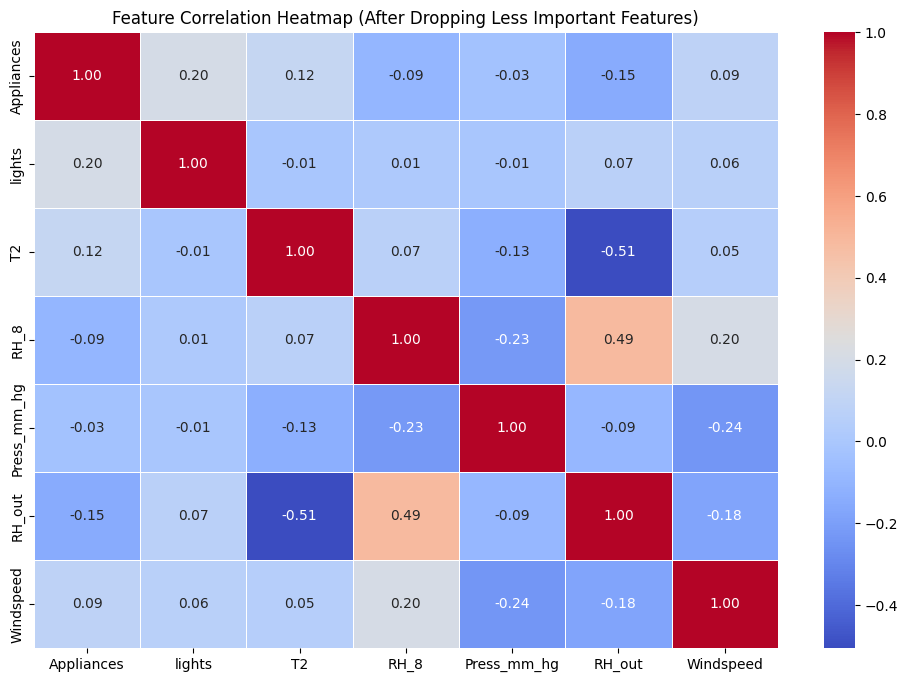

In [ ]:
correlation_matrix = df.corr()
corr_with_target = correlation_matrix["Appliances"].abs().sort_values(ascending=False)

highly_corr_features = corr_with_target[corr_with_target > 0.03].index.tolist()
weak_corr_features = corr_with_target[corr_with_target < 0.03].index.tolist()

df.drop(columns=weak_corr_features, inplace=True)
print(f"Removed weak correlation features: {weak_corr_features}")

correlation_matrix = df.corr()
corr_threshold = 0.7
high_corr_pairs = set()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > corr_threshold:
            feature_1 = correlation_matrix.columns[i]
            feature_2 = correlation_matrix.columns[j]

            if corr_with_target[feature_1] > corr_with_target[feature_2]:
                high_corr_pairs.add(feature_2)
            else:
                high_corr_pairs.add(feature_1)

df.drop(columns=high_corr_pairs, inplace=True)
print(f"Dropped highly correlated features: {high_corr_pairs}")

print(f"Final selected features: {list(df.columns)}")

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt='.2f' , linewidths=0.5)
plt.title("Feature Correlation Heatmap (After Dropping Less Important Features)")
plt.show()

In [ ]:
df = pd.concat([df_copied['date'], df], axis=1)

In [ ]:
lag_features = ['Appliances', 'lights', 'T2', 'RH_out']
for col in lag_features:
    df[f"{col}_lag_1"] = df[col].shift(1)
    df[f"{col}_lag_3"] = df[col].shift(3)

rolling_features = ['Appliances', 'T2', 'RH_8', 'Press_mm_hg', 'RH_out', 'Windspeed', 'lights']

for col in rolling_features:
    df[f"{col}_rolling_3"] = df[col].rolling(window=3).mean()
    df[f"{col}_rolling_6"] = df[col].rolling(window=6).mean()


df['hour'] = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month

df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['day_of_week_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['day_of_week_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

max_na_cutoff = max(3, 6)
df = df.iloc[max_na_cutoff:]

df.drop(columns=['hour', 'day_of_week', 'month'], inplace=True)
df.head(2)

<ipython-input-82-d98d44cc5089>:25: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,date,Appliances,lights,T2,RH_8,Press_mm_hg,RH_out,Windspeed,Appliances_lag_1,Appliances_lag_3,...,RH_out_rolling_3,RH_out_rolling_6,Windspeed_rolling_3,Windspeed_rolling_6,lights_rolling_3,lights_rolling_6,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
6,2016-01-11 18:00:00,60,50,19.2,48.59,734.100000,92.000000,5.000000,50.0,50.0,...,92.000000,92.000000,5.333333,5.833333,43.333333,38.333333,-1.0,-1.836970e-16,0.0,1.0
7,2016-01-11 18:10:00,60,50,19.2,48.59,734.166667,91.833333,5.166667,60.0,60.0,...,91.944444,91.972222,5.166667,5.583333,46.666667,41.666667,-1.0,-1.836970e-16,0.0,1.0


Cross-Validation Results: {'Mean MSE (TimeSeriesSplit)': 1879.0306409976463, 'Std MSE (TimeSeriesSplit)': 312.6417324442517, 'Mean R² (TimeSeriesSplit)': 0.8039409747749392, 'Std R² (TimeSeriesSplit)': 0.029284657701137504, 'R² Scores (Each Fold)': [0.7738990739004205, 0.8307271761473902, 0.8306973061754439, 0.7632433068620481, 0.821138010789394], 'MSE Scores (Each Fold)': [2196.9477815869245, 1824.2991370274556, 1660.5549534203997, 2266.5087438920323, 1446.8425890614199]}


 96%|=================== | 15228/15783 [00:15<00:00]       

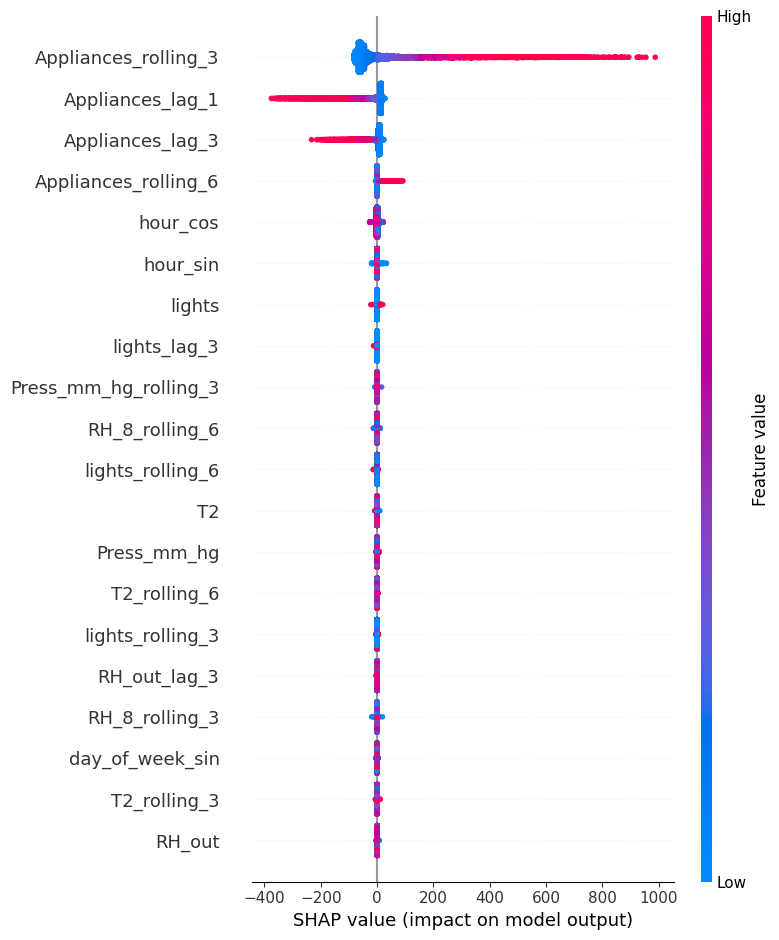

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import shap


scaler = MinMaxScaler()
continuous_features = df.select_dtypes(include=['float64', 'int64']).columns.difference(['Appliances'])
df[continuous_features] = scaler.fit_transform(df[continuous_features])

X = df.drop(columns=['Appliances', 'date'])
y = df['Appliances']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)


tscv = TimeSeriesSplit(n_splits=5)

mse_scores = []
r2_scores = []

for train_index, test_index in tscv.split(X):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    gbm = GradientBoostingRegressor(random_state=42)
    gbm.fit(X_train_fold, y_train_fold)

    y_pred_fold = gbm.predict(X_test_fold)
    mse_scores.append(mean_squared_error(y_test_fold, y_pred_fold))
    r2_scores.append(r2_score(y_test_fold, y_pred_fold))


cv_results = {
    "Mean MSE (TimeSeriesSplit)": np.mean(mse_scores),
    "Std MSE (TimeSeriesSplit)": np.std(mse_scores),
    "Mean R² (TimeSeriesSplit)": np.mean(r2_scores),
    "Std R² (TimeSeriesSplit)": np.std(r2_scores),
    "R² Scores (Each Fold)": r2_scores,
    "MSE Scores (Each Fold)": mse_scores
}

print("Cross-Validation Results:", cv_results)


explainer = shap.Explainer(gbm, X_train)
shap_values = explainer(X_train)


shap.summary_plot(shap_values, X_train)

In [ ]:
X_train = X_train[['Appliances_lag_1', 'Appliances_lag_3', 'Appliances_rolling_3', 'Appliances_rolling_6', 'hour_sin', 'lights']]
X_test = X_test[['Appliances_lag_1', 'Appliances_lag_3', 'Appliances_rolling_3', 'Appliances_rolling_6', 'hour_sin', 'lights']]

In [ ]:
df_new = pd.concat([X_train, y], axis=1)

forecast_steps = [1, 3, 6]  #10 min, 30 min, and 1 hour ahead
for step in forecast_steps:
    df_new[f'Appliances_next_{step}'] = df_new['Appliances'].shift(-step)

df_new = df_new.dropna()
X = df_new.drop(columns=['Appliances', 'Appliances_next_1', 'Appliances_next_3', 'Appliances_next_6'])
y_10min = df_new['Appliances_next_1']
y_30min = df_new['Appliances_next_3']
y_1hour = df_new['Appliances_next_6']



df_new.shape

(15783, 10)

Test MSE: 1449.1075569824218
Test R²: 0.824799451548743


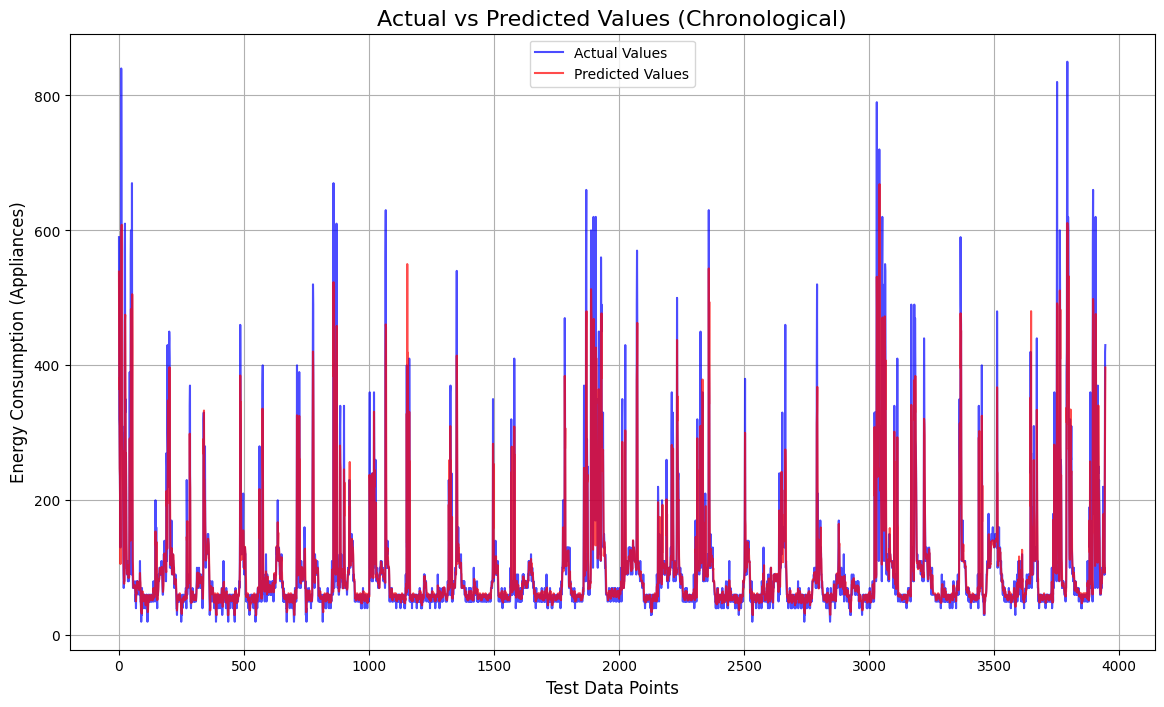

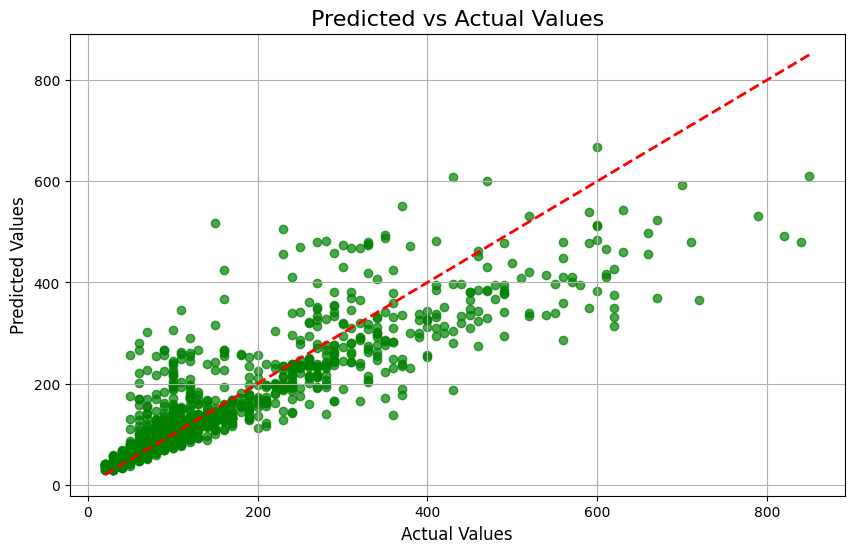

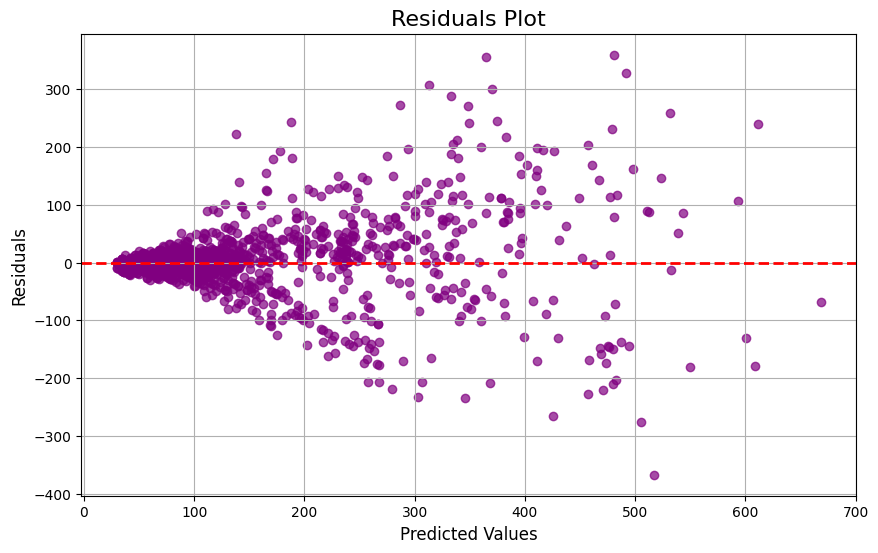

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

#Final model with the best parameters
Featu10_gbm = GradientBoostingRegressor(
    learning_rate=0.01,
    max_depth=5,
    n_estimators=300,
    subsample=0.8,
    random_state=42
)
Featu10_gbm.fit(X_train, y_train)

y_pred = Featu10_gbm.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {test_mse}")
print(f"Test R²: {test_r2}")

#Actual vs Predicted values
plt.figure(figsize=(14, 8))
plt.plot(range(len(y_test)), y_test, label='Actual Values', color='blue', alpha=0.7)
plt.plot(range(len(y_test)), y_pred, label='Predicted Values', color='red', alpha=0.7)
plt.title('Actual vs Predicted Values (Chronological)', fontsize=16)
plt.xlabel('Test Data Points', fontsize=12)
plt.ylabel('Energy Consumption (Appliances)', fontsize=12)
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Predicted vs Actual Values', fontsize=16)
plt.xlabel('Actual Values', fontsize=12)
plt.ylabel('Predicted Values', fontsize=12)
plt.grid()
plt.show()

#Residuals
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.title('Residuals Plot', fontsize=16)
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid()
plt.show()

10-Minute Forecast - MSE: 5513.249844787463, R²: 0.43135498224563973
30-Minute Forecast - MSE: 7571.730179624471, R²: 0.21750153014573403
1-Hour Forecast - MSE: 7771.180556124253, R²: 0.19386432150066768


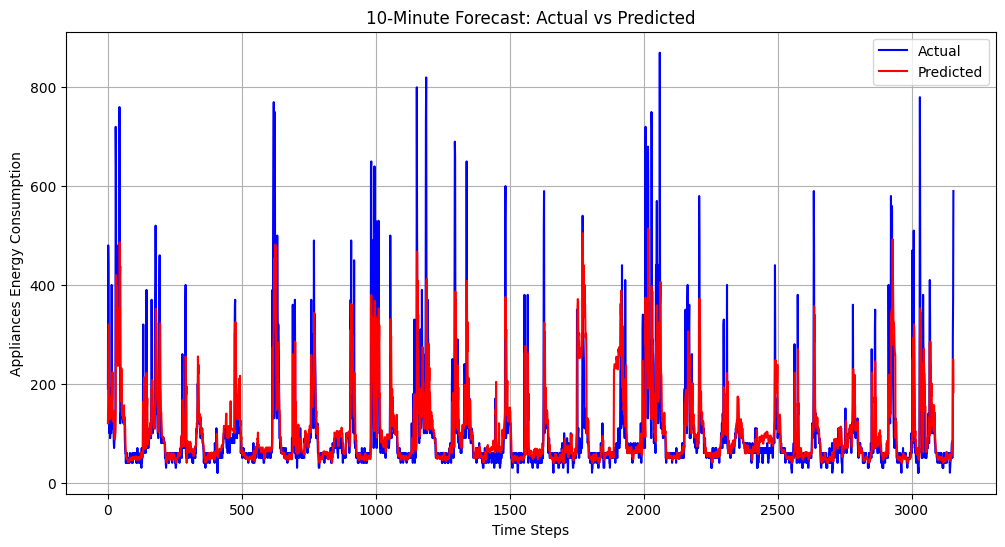

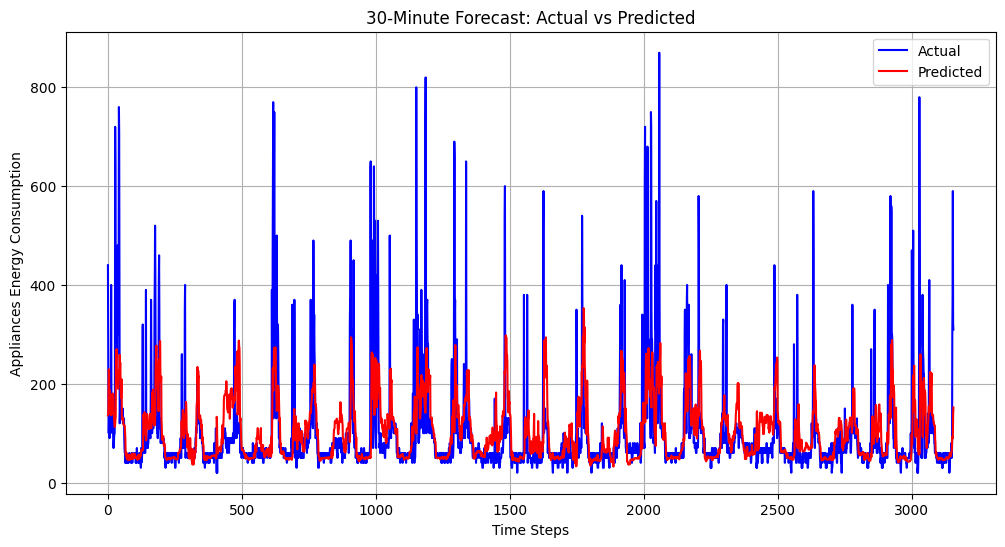

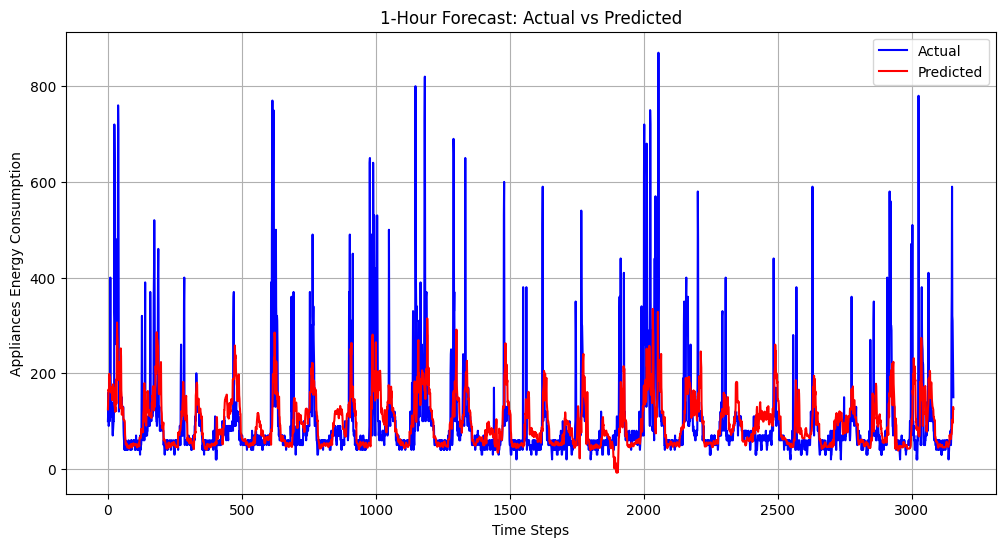

In [ ]:
# Example: Gradient Boosting Regressor for 10-minute forecast
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

#10-minute
gbm_10min = GradientBoostingRegressor(random_state=42)
gbm_10min.fit(X_train_10min, y_train_10min)

y_pred_10min = gbm_10min.predict(X_test_10min)
mse_10min = mean_squared_error(y_test_10min, y_pred_10min)
r2_10min = r2_score(y_test_10min, y_pred_10min)

print(f"10-Minute Forecast - MSE: {mse_10min}, R²: {r2_10min}")

#30-minutes
gbm_30min = GradientBoostingRegressor(random_state=42)
gbm_30min.fit(X_train_30min, y_train_30min)

y_pred_30min = gbm_30min.predict(X_test_30min)
mse_30min = mean_squared_error(y_test_30min, y_pred_30min)
r2_30min = r2_score(y_test_30min, y_pred_30min)

print(f"30-Minute Forecast - MSE: {mse_30min}, R²: {r2_30min}")

#1-hour
gbm_1hour = GradientBoostingRegressor(random_state=42)
gbm_1hour.fit(X_train_1hour, y_train_1hour)

y_pred_1hour = gbm_1hour.predict(X_test_1hour)
mse_1hour = mean_squared_error(y_test_1hour, y_pred_1hour)
r2_1hour = r2_score(y_test_1hour, y_pred_1hour)

print(f"1-Hour Forecast - MSE: {mse_1hour}, R²: {r2_1hour}")


#Actual vs predicted for 10-minute,30_minute and 1-hour forecast
plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_10min)), y_test_10min, label='Actual', color='blue')
plt.plot(range(len(y_pred_10min)), y_pred_10min, label='Predicted', color='red')
plt.title('10-Minute Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_30min)), y_test_30min, label='Actual', color='blue')
plt.plot(range(len(y_pred_30min)), y_pred_30min, label='Predicted', color='red')
plt.title('30-Minute Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(range(len(y_test_1hour)), y_test_1hour, label='Actual', color='blue')
plt.plot(range(len(y_pred_1hour)), y_pred_1hour, label='Predicted', color='red')
plt.title('1-Hour Forecast: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Appliances Energy Consumption')
plt.legend()
plt.grid()
plt.show()